# 4 · Validazione su immagini sintetiche

I dati reali non hanno una verità a terra: l'errore misurato mescola l'algoritmo e il setup. Qui la scena è nota: una camera con i parametri stimati sul setup reale, un master di cerchi, una lama di luce e un solido con profilo nominale. `lightsheet3d.synthetic` genera le immagini con gli stessi nomi e formato di quelle reali, la pipeline le legge senza modifiche e il risultato si confronta con la geometria vera.

Il rumore è uno spostamento gaussiano (in pixel) dei centri dei cerchi e dei punti della lama prima del disegno.

In [1]:
import tempfile
from pathlib import Path

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "docs" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

from lightsheet3d.solids import CORPO6
from lightsheet3d.synthetic import Scene, evaluate, render_master, render_scan

## Immagini generate

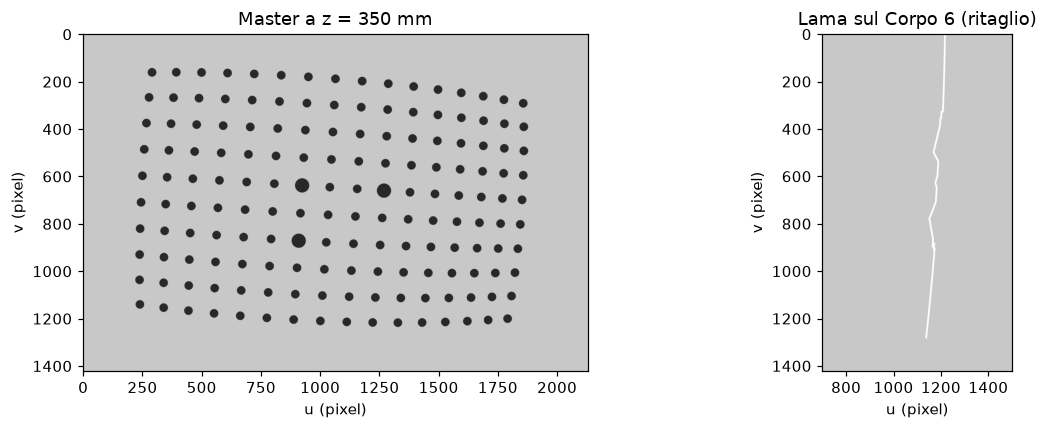

In [2]:
scene = Scene()
master = render_master(scene, 350)
scan = render_scan(scene, CORPO6, shift=-57.0)

fig, axs = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [2.4, 1]})
axs[0].imshow(cv.cvtColor(master, cv.COLOR_BGR2RGB)); axs[0].set_title("Master a z = 350 mm")
axs[1].imshow(cv.cvtColor(scan[:, 700:1500], cv.COLOR_BGR2RGB), extent=(700, 1500, scan.shape[0], 0)); axs[1].set_title("Lama sul Corpo 6 (ritaglio)")
for ax in axs:
    ax.grid(False); ax.set(xlabel="u (pixel)", ylabel="v (pixel)")
fig.tight_layout(); fig.savefig(FIGURES / "synthetic_images.png", bbox_inches="tight")

## Errore contro rumore

Per ogni livello di rumore si genera un dataset (master a cinque quote, lama sul master, scansione), si calibra e si misura. L'errore è la distanza di ogni punto 3D dal profilo nominale vero, nel piano (y, h).

In [3]:
NOISE = [0.0, 0.25, 0.5, 1.0, 2.0]
SEEDS = range(3)
med, p90 = {}, {}
with tempfile.TemporaryDirectory() as tmp:
    for sigma in NOISE:
        runs = [evaluate(CORPO6, Path(tmp) / f"{sigma}_{seed}", noise_px=sigma, seed=seed) for seed in SEEDS]
        med[sigma] = [np.median(r["dist"]) for r in runs]
        p90[sigma] = [np.percentile(r["dist"], 90) for r in runs]
        print(f"rumore {sigma:4.2f} px: distanza mediana {np.mean(med[sigma]):.3f} mm, 90° percentile {np.mean(p90[sigma]):.3f} mm, "
              f"scarto traslazione {np.mean([abs(r['shift'] + 57) for r in runs]):.2f} mm")

rumore 0.00 px: distanza mediana 0.099 mm, 90° percentile 0.396 mm, scarto traslazione 0.01 mm


rumore 0.25 px: distanza mediana 0.137 mm, 90° percentile 0.496 mm, scarto traslazione 0.02 mm


rumore 0.50 px: distanza mediana 0.211 mm, 90° percentile 0.772 mm, scarto traslazione 0.03 mm


rumore 1.00 px: distanza mediana 0.373 mm, 90° percentile 1.277 mm, scarto traslazione 0.06 mm


rumore 2.00 px: distanza mediana 0.644 mm, 90° percentile 1.984 mm, scarto traslazione 0.11 mm


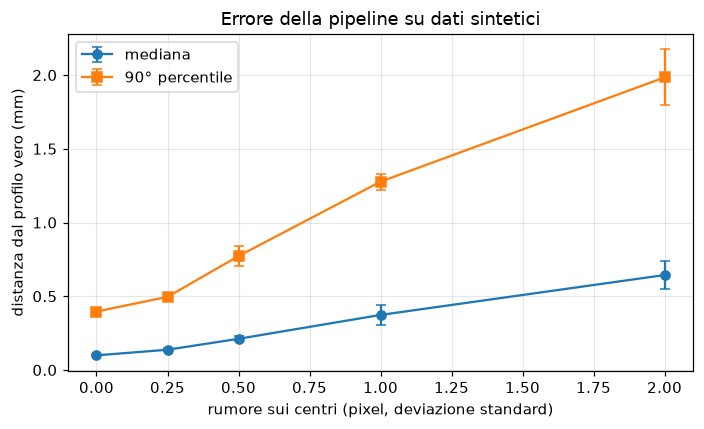

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for series, label, marker in ((med, "mediana", "o"), (p90, "90° percentile", "s")):
    mean = [np.mean(series[s]) for s in NOISE]
    spread = [np.ptp(series[s]) / 2 for s in NOISE]
    ax.errorbar(NOISE, mean, yerr=spread, marker=marker, capsize=3, label=label)
ax.set(xlabel="rumore sui centri (pixel, deviazione standard)", ylabel="distanza dal profilo vero (mm)",
       title="Errore della pipeline su dati sintetici"); ax.legend()
fig.tight_layout(); fig.savefig(FIGURES / "synthetic_error_vs_noise.png", bbox_inches="tight")

## Cosa mostra

* **Senza rumore** l'errore non è zero: la lama ha spessore e i punti sono campionati per riga, quindi i fianchi molto ripidi hanno pochi punti.
* **Altezza dei picchi**: i picchi acuti risultano sottostimati di circa 0.5 mm anche senza rumore (filtro mediano di `measure_peaks` e campionamento): è un bias dell'algoritmo, non del setup.
* **Deriva degli offset**: prima di fissare il gauge in `fit_camera`, la calibrazione inventava un offset del master lineare in z anche quando il master non si muoveva, con un errore sistematico di circa 0.25 mm (test in `tests/test_synthetic.py`).